# **Extracting Information from Legal Documents Using RAG**

## **Objective**

The main objective of this assignment is to process and analyse a collection text files containing legal agreements (e.g., NDAs) to prepare them for implementing a **Retrieval-Augmented Generation (RAG)** system. This involves:

* Understand the Cleaned Data : Gain a comprehensive understanding of the structure, content, and context of the cleaned dataset.
* Perform Exploratory Analysis : Conduct bivariate and multivariate analyses to uncover relationships and trends within the cleaned data.
* Create Visualisations : Develop meaningful visualisations to support the analysis and make findings interpretable.
* Derive Insights and Conclusions : Extract valuable insights from the cleaned data and provide clear, actionable conclusions.
* Document the Process : Provide a detailed description of the data, its attributes, and the steps taken during the analysis for reproducibility and clarity.

The ultimate goal is to transform the raw text data into a clean, structured, and analysable format that can be effectively used to build and train a RAG system for tasks like information retrieval, question-answering, and knowledge extraction related to legal agreements.

### **Business Value**  


The project aims to leverage RAG to enhance legal document processing for businesses, law firms, and regulatory bodies. The key business objectives include:

* Faster Legal Research: <br> Reduce the time lawyers and compliance officers spend searching for relevant case laws, precedents, statutes, or contract clauses.
* Improved Contract Analysis: <br> Automatically extract key terms, obligations, and risks from lengthy contracts.
* Regulatory Compliance Monitoring: <br> Help businesses stay updated with legal and regulatory changes by retrieving relevant legal updates.
* Enhanced Decision-Making: <br> Provide accurate and context-aware legal insights to assist in risk assessment and legal strategy.


**Use Cases**
* Legal Chatbots
* Contract Review Automation
* Tracking Regulatory Changes and Compliance Monitoring
* Case Law Analysis of past judgments
* Due Diligence & Risk Assessment

## **1. Data Loading, Preparation and Analysis** <font color=red> [20 marks] </font><br>

### **1.1 Data Understanding**

The dataset contains legal documents and contracts collected from various sources. The documents are present as text files (`.txt`) in the *corpus* folder.

There are four types of documents in the *courpus* folder, divided into four subfolders.
- `contractnli`: contains various non-disclosure and confidentiality agreements
- `cuad`: contains contracts with annotated legal clauses
- `maud`: contains various merger/acquisition contracts and agreements
- `privacy_qa`: a question-answering dataset containing privacy policies

The dataset also contains evaluation files in JSON format in the *benchmark* folder. The files contain the questions and their answers, along with sources. For the above folders, there is a `json` file: `contractnli.json`, `cuad.json`, `maud.json`. The file structure is as follows:

```
{
    "tests": [
        {
            "query": <question1>,
            "snippets": [{
                    "file_path": <source_file1>,
                    "span": [ begin_position, end_position ],
                    "answer": <relevant answer to the question 1>
                },
                {
                    "file_path": <source_file2>,
                    "span": [ begin_position, end_position ],
                    "answer": <relevant answer to the question 2>
                }, ....
            ]
        },
        {
            "query": <question2>,
            "snippets": [{<answer context for que 2>}]
        },
        ... <more queries>
    ]
}
```

### **1.2 Load and Preprocess the data** <font color=red> [5 marks] </font><br>

#### Loading libraries

In [ ]:
## The following libraries might be useful
!pip install -q langchain-openai
!pip install -U -q langchain-community
!pip install -U -q langchain-chroma
!pip install -U -q datasets
!pip install -U -q ragas
!pip install -U -q rouge_score


[notice] A new release of pip is available: 26.2.1 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip

[notice] A new release of pip is available: 26.2.1 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip

[notice] A new release of pip is available: 26.2.1 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
langchain-huggingface 1.2.0 requires huggingface-hub<1.0.0,>=0.33.4, but you have huggingface-hub 2.2.0 which is incompatible.
tokenizers 0.22.2 requires huggingface-hub<2.0,>=0.16.4, but you have huggingface-hub 2.2.0 which is incompatible.
transformers 4.57.6 requires huggingface-hub<1.0,>=0.34.0, but you have huggingface-hub 2.2.0 which is incompatible.

[notice] A new release of pip is available: 26.2.1 -> 26.2.2
[notice] To update, run

In [1]:
# Import essential libraries
import os
from collections import Counter

from langchain_community.document_loaders import DirectoryLoader, TextLoader


C:\Users\rituP\AppData\Local\Temp\ipykernel_6036\3165146143.py:5: DeprecationWarning: `langchain-community` is being sunset and is no longer actively maintained. See https://github.com/langchain-ai/langchain-community/issues/674 for details and migration guidance toward standalone integration packages.
  from langchain_community.document_loaders import DirectoryLoader, TextLoader


#### **1.2.1** <font color=red> [3 marks] </font>
Load all `.txt` files from the folders.

You can utilise document loaders from the options provided by the LangChain community.

Optionally, you can also read the files manually, while ensuring proper handling of encoding issues (e.g., utf-8, latin1). In such case, also store the file content along with metadata (e.g., file name, directory path) for traceability.

In [ ]:
# Load the files as documents
# Use document loaders to load the text files as documents. You can use the TextLoader from langchain.document_loaders to load the text files.
CORPUS_DIR = r"C:\Ritu Data\Upgrad\GenAI\RAG_Assignment\rag_legal\corpus"

def load_files_as_documents(corpus_dir):
    """Recursively load all .txt files with LangChain's DirectoryLoader + TextLoader.
    autodetect_encoding=True tries to detect the encoding (utf-8, latin-1, ...) when a file
    can't be read as utf-8; silent_errors=True skips unreadable files instead of stopping."""
    loader = DirectoryLoader(
        corpus_dir,
        glob="**/*.txt",
        loader_cls=TextLoader,
        loader_kwargs={"autodetect_encoding": True},
        recursive=True,
        silent_errors=True,
        show_progress=True,
    )
    documents = loader.load()

    # Add metadata for traceability
    for document in documents:
        file_path = document.metadata["source"]
        document.metadata["file_name"] = os.path.basename(file_path)
        document.metadata["folder"] = os.path.basename(os.path.dirname(file_path))   # contractnli / cuad / maud / privacy_qa
        document.metadata["rel_path"] = os.path.relpath(file_path, corpus_dir)
    return documents

docs = load_files_as_documents(CORPUS_DIR)

# Sanity checks
print(f"Loaded {len(docs)} documents")
print(Counter(document.metadata["folder"] for document in docs))
print(f"Source: {docs[0].metadata['file_name']}, Path: {docs[0].metadata['rel_path']}")
print(f"Page Content: {docs[0].page_content[:300]}")


#### **1.2.2** <font color=red> [2 marks] </font>
Preprocess the text data to remove noise and prepare it for analysis.

Remove special characters, extra whitespace, and irrelevant content such as email and telephone contact info.
Normalise text (e.g., convert to lowercase, remove stop words).
Handle missing or corrupted data by logging errors and skipping problematic files.

In [ ]:
 !pip install -q nltk


[notice] A new release of pip is available: 26.2.1 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip


In [3]:
# Clean and preprocess the data
import re
import logging
import nltk
from nltk.corpus import stopwords
from langchain_core.documents import Document

nltk.download("stopwords", quiet=True)
STOP_WORDS = set(stopwords.words("english"))

logging.basicConfig(level=logging.INFO, format="%(levelname)s: %(message)s")
logger = logging.getLogger("preprocess")

EMAIL_RE = re.compile(r"[\w\.\-+]+@[\w\-]+(?:\.[\w\-]+)+")
URL_RE = re.compile(r"(?:https?://|www\.)\S+")
PHONE_RE = re.compile(r"(?:\+?\d{1,3}[\s.\-]?)?(?:\(\d{2,4}\)[\s.\-]?)?\d{3,4}[\s.\-]\d{3,4}(?:[\s.\-]\d{2,4})?")
SPECIAL_RE = re.compile(r"[^a-z0-9\s]")
SPACE_RE = re.compile(r"\s+")

def clean_text(text, remove_stopwords=True):
    """Remove emails/URLs/phone numbers and special characters, normalise to lowercase,
    collapse whitespace and (optionally) drop stop words."""
    text = EMAIL_RE.sub(" ", text)
    text = URL_RE.sub(" ", text)
    text = PHONE_RE.sub(" ", text)
    text = text.lower()
    text = SPECIAL_RE.sub(" ", text)
    text = SPACE_RE.sub(" ", text).strip()
    if remove_stopwords:
        text = " ".join(word for word in text.split() if word not in STOP_WORDS)
    return text

def preprocess_documents(documents):
    """Return cleaned copies of the documents. Empty/corrupted ones are logged and skipped.
    The original text is kept in metadata['original_text'] (useful for chunking/benchmark spans)."""
    cleaned_docs, skipped_files = [], []
    for document in documents:
        source_path = document.metadata.get("source", "unknown")
        try:
            if document.page_content is None or not document.page_content.strip():
                raise ValueError("empty document")
            cleaned_text = clean_text(document.page_content)
            if not cleaned_text:
                raise ValueError("no content left after cleaning")
            metadata = dict(document.metadata)
            metadata["original_text"] = document.page_content
            cleaned_docs.append(Document(page_content=cleaned_text, metadata=metadata))
        except Exception as error:
            logger.error("Skipping %s: %s", source_path, error)
            skipped_files.append(source_path)
    print(f"Cleaned {len(cleaned_docs)} documents; skipped {len(skipped_files)}")
    return cleaned_docs

cleaned_docs = preprocess_documents(docs)

# Before/after check
print("BEFORE:", docs[0].page_content[:300])
print("AFTER :", cleaned_docs[0].page_content[:300])


Cleaned 644 documents; skipped 0
BEFORE: MUTUAL NON-DISCLOSURE AGREEMENT
Between
AND
Subject Matter:
Effective Date of Agreement: Period , 2017
for Exchange of Information: , 2017 to
Period of Confidentiality:
THIS AGREEMENT is made as of the Effective Date of Agreement noted above, by and between the above parties.
BACKGROUND:
I. The part
AFTER : mutual non disclosure agreement subject matter effective date agreement period 2017 exchange information 2017 period confidentiality agreement made effective date agreement noted parties background parties desire discussions relating subject matter purposes evaluating possible business relationship 


### **1.3 Exploratory Data Analysis** <font color=red> [10 marks] </font><br>

#### **1.3.1** <font color=red> [2 marks] </font>
Calculate the average, maximum and minimum document length.

In [4]:
# Calculate the average, maximum and minimum document length.
import pandas as pd

# Length in words (cleaned text) and in characters (original text)
lengths = pd.DataFrame({
    "file_name": [document.metadata["file_name"] for document in cleaned_docs],
    "folder": [document.metadata["folder"] for document in cleaned_docs],
    "word_count": [len(document.page_content.split()) for document in cleaned_docs],
    "char_count": [len(document.metadata["original_text"]) for document in cleaned_docs],
})

# Overall statistics
print("Document length (words, after cleaning):")
print(f"  Average: {lengths['word_count'].mean():.1f}")
print(f"  Maximum: {lengths['word_count'].max()}  ({lengths.loc[lengths['word_count'].idxmax(), 'file_name']})")
print(f"  Minimum: {lengths['word_count'].min()}  ({lengths.loc[lengths['word_count'].idxmin(), 'file_name']})")

print("\nDocument length (characters, original text):")
print(f"  Average: {lengths['char_count'].mean():.1f}")
print(f"  Maximum: {lengths['char_count'].max()}")
print(f"  Minimum: {lengths['char_count'].min()}")

# Breakdown by document type (folder)
print("\nWord count by folder:")
print(lengths.groupby("folder")["word_count"].agg(["count", "mean", "max", "min"]).round(1))


Document length (words, after cleaning):
  Average: 8803.3
  Maximum: 87534  (Contango_Oil_&_Gas_KKR_&_Co.txt)
  Minimum: 152  (GALACTICOMMTECHNOLOGIESINC_11_07_1997-EX-10.46-WEB HOSTING AGREEMENT.txt)

Document length (characters, original text):
  Average: 99514.0
  Maximum: 999236
  Minimum: 1660

Word count by folder:
             count     mean    max   min
folder                                  
contractnli     93    903.4   2769   214
cuad           431   4694.2  26709   152
maud           117  30404.2  87534  9628
privacy_qa       3   1604.3   2392   263


#### **1.3.2** <font color=red> [4 marks] </font>
Analyse the frequency of occurence of words and find the most and least occuring words.

Find the 20 most common and least common words in the text. Ignore stop words such as articles and prepositions.

Total words: 5150201, unique words: 26843

20 most common words:
  company             135777
  shall               95630
  agreement           92938
  section             65872
  parent              54884
  party               48773
  date                34571
  time                31463
  merger              29835
  material            29436
  subsidiaries        28989
  applicable          27381
  including           25825
  respect             25403
  may                 24688
  stock               22794
  information         22558
  parties             21897
  business            20840
  prior               20617

20 least common words:
  aaaaaaaaaa          1
  aai                 1
  aaldo               1
  aam                 1
  aarphealthcare      1
  aarpmagazine        1
  abbey               1
  abbott              1
  abduction           1
  abel                1
  abetting            1
  abides              1
  abigail             1
  abington            1
  ably        

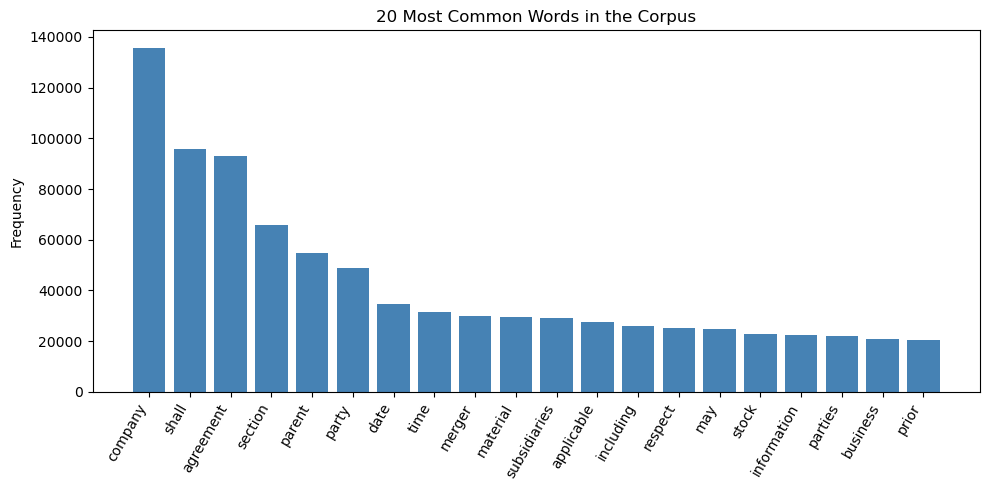

In [5]:
# Find frequency of occurence of words
from collections import Counter
import matplotlib.pyplot as plt

# Count words across all cleaned documents (stop words are already removed).
# Keep only alphabetic tokens of 3+ letters to avoid numbers and leftover fragments.
word_counts = Counter()
for document in cleaned_docs:
    word_counts.update(word for word in document.page_content.split() if word.isalpha() and len(word) >= 3)

print(f"Total words: {sum(word_counts.values())}, unique words: {len(word_counts)}")

# 20 most common words
most_common = word_counts.most_common(20)
print("\n20 most common words:")
for word, count in most_common:
    print(f"  {word:<20}{count}")

# 20 least common words (many words appear exactly once, so ties are broken alphabetically)
least_common = sorted(word_counts.items(), key=lambda word_and_count: (word_and_count[1], word_and_count[0]))[:20]
print("\n20 least common words:")
for word, count in least_common:
    print(f"  {word:<20}{count}")

hapax = sum(1 for count in word_counts.values() if count == 1)
print(f"\nWords that occur only once: {hapax} ({hapax / len(word_counts):.1%} of vocabulary)")

# Bar chart of the most common words
top_words, top_counts = zip(*most_common)
plt.figure(figsize=(10, 5))
plt.bar(top_words, top_counts, color="steelblue")
plt.xticks(rotation=60, ha="right")
plt.title("20 Most Common Words in the Corpus")
plt.ylabel("Frequency")
plt.tight_layout()
plt.show()


#### **1.3.3** <font color=red> [4 marks] </font>
Analyse the similarity of different documents to each other based on TF-IDF vectors.

Transform some documents to TF-IDF vectors and calculate their similarity matrix using a suitable distance function. If contracts contain duplicate or highly similar clauses, similarity calculation can help detect them.

Identify for the first 10 documents and then for 10 random documents. What do you observe?

TF-IDF matrix shape: (644, 20000)


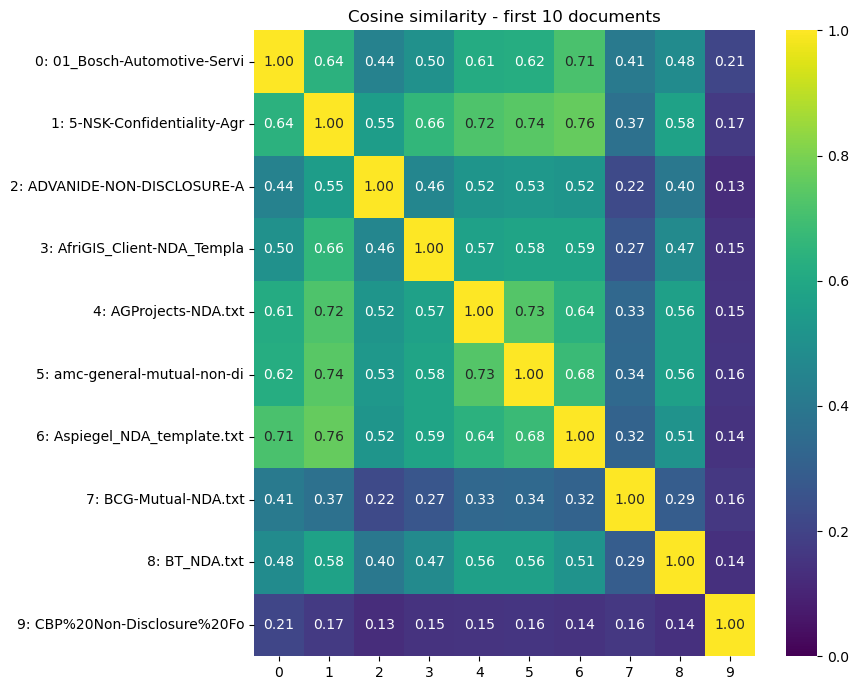

Most similar pair: 1: 5-NSK-Confidentiality-Agr  <->  6: Aspiegel_NDA_template.txt  (score 0.76)
Average pairwise similarity: 0.45


In [6]:
# Transform the page contents of documents
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics.pairwise import cosine_similarity

# Fit TF-IDF on the whole cleaned corpus so IDF weights reflect all documents
texts = [document.page_content for document in cleaned_docs]
names = [document.metadata["file_name"][:25] for document in cleaned_docs]

tfidf = TfidfVectorizer(max_features=20000)
tfidf_matrix = tfidf.fit_transform(texts)
print("TF-IDF matrix shape:", tfidf_matrix.shape)

def similarity_report(indices, title):
    """Cosine similarity matrix for the given documents, shown as a heatmap."""
    similarity_matrix = cosine_similarity(tfidf_matrix[indices])
    labels = [f"{doc_idx}: {names[doc_idx]}" for doc_idx in indices]
    similarity_df = pd.DataFrame(similarity_matrix, index=labels, columns=indices)
    plt.figure(figsize=(9, 7))
    sns.heatmap(similarity_df, annot=True, fmt=".2f", cmap="viridis", vmin=0, vmax=1)
    plt.title(title)
    plt.tight_layout()
    plt.show()

    # Most similar pair (excluding the diagonal)
    off_diagonal = similarity_matrix.copy()
    np.fill_diagonal(off_diagonal, -1)
    first_idx, second_idx = np.unravel_index(off_diagonal.argmax(), off_diagonal.shape)
    print(f"Most similar pair: {labels[first_idx]}  <->  {labels[second_idx]}  (score {off_diagonal[first_idx, second_idx]:.2f})")
    print(f"Average pairwise similarity: {off_diagonal[off_diagonal >= 0].mean():.2f}")
    return similarity_matrix

# Compute similarity scores
# Compute similarity scores for the first 10 documents
first_10 = list(range(10))
sim_first = similarity_report(first_10, "Cosine similarity - first 10 documents")


In [7]:
# create a list of 10 random integers
import random
random.seed(42)
random_10 = random.sample(range(len(cleaned_docs)), 10)
print(random_10)


[114, 25, 281, 250, 228, 142, 104, 558, 89, 604]


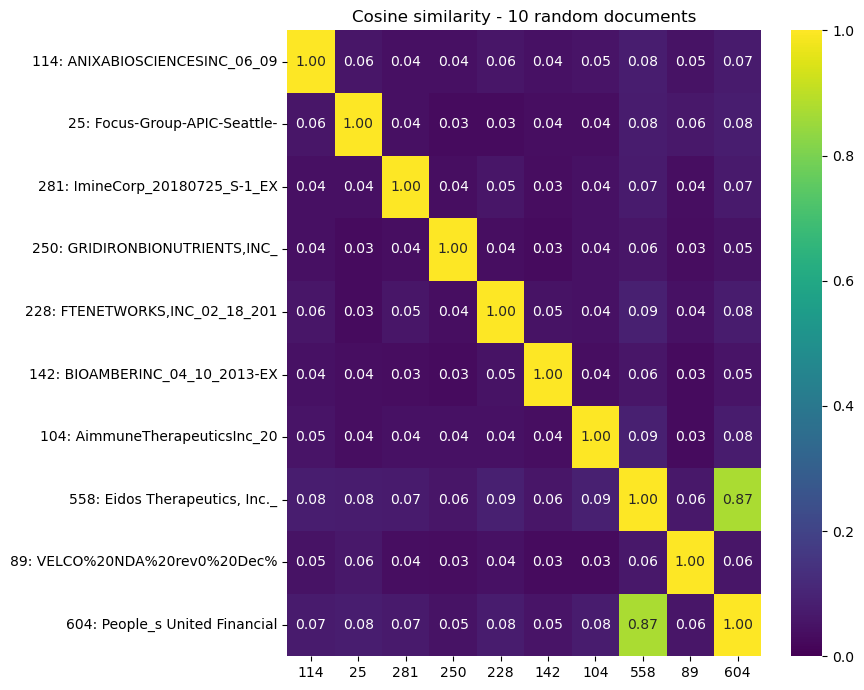

Most similar pair: 558: Eidos Therapeutics, Inc._  <->  604: People_s United Financial  (score 0.87)
Average pairwise similarity: 0.07


In [8]:
# Compute similarity scores for 10 random documents
sim_random = similarity_report(random_10, "Cosine similarity - 10 random documents")


#### **Observations**

**First 10 documents (all `contractnli` NDAs)**
- Similarity is high and consistent: the average pairwise cosine score is about 0.45, and most pairs score between 0.4 and 0.75.
- The most similar pair is `5-NSK-Confidentiality-Agreement-for-Suppliers` and `Aspiegel_NDA_template` (about 0.76). NDAs share the same standard clauses, such as definition of confidential information, obligations, term, return of materials and governing law. They are written from near-identical templates, so they use much of the same vocabulary.
- The exceptions are the last document (about 0.13 to 0.21 against every other) and, to a lesser degree, the eighth (about 0.22 to 0.41). These documents are probably structured differently, for example as a data-use or policy-style agreement, or they have unusual wording.

**10 random documents (mixed `cuad`, `maud` and `contractnli`)**
- Similarity is very low: the average pairwise score is about 0.07, and almost every pair is under 0.10. The documents come from different types of agreements (distribution, endorsement, joint venture, merger, NDA), so their vocabulary has little in common.
- The one exception is a pair of `maud` merger agreements, `Eidos Therapeutics / BridgeBio Pharma` and `People's United Financial / M&T Bank`, at about 0.87. They are the same kind of document, and merger agreements reuse long boilerplate sections.

**Takeaways**
- TF-IDF similarity picks out documents of the same type. NDAs are similar to each other, and merger agreements are similar to each other, while mixed contract types are not.
- Highly similar documents share duplicated or near-duplicated clauses. For RAG, this means retrieval may return near-identical chunks from different contracts. That argues for metadata filtering by document or source, deduplication, or re-ranking.
- The contrast between the two samples shows that the corpus is clustered by document type (`contractnli`, `cuad`, `maud`, `privacy_qa`). Retrieval quality may therefore depend on which kind of question is asked.


### **1.4 Document Creation and Chunking** <font color=red> [5 marks] </font><br>

#### **1.4.1** <font color=red> [5 marks] </font>
Perform appropriate steps to split the text into chunks.

In [9]:
# Process files and generate chunks
from langchain_text_splitters import RecursiveCharacterTextSplitter

# Split the original (uncleaned) documents: embeddings and answer generation work better on
# natural text, and the benchmark answer spans refer to the original text.
text_splitter = RecursiveCharacterTextSplitter(
    chunk_size=1000,
    chunk_overlap=200,
    separators=["\n\n", "\n", ". ", " ", ""],
    add_start_index=True,      # stores the character offset of each chunk in metadata["start_index"]
)

chunks = text_splitter.split_documents(docs)

# Sanity checks
chunk_lengths = [len(chunk.page_content) for chunk in chunks]
print(f"{len(docs)} documents -> {len(chunks)} chunks")
print(f"Chunk length (chars): avg {sum(chunk_lengths)/len(chunk_lengths):.0f}, max {max(chunk_lengths)}, min {min(chunk_lengths)}")
print(Counter(chunk.metadata["folder"] for chunk in chunks))
print(chunks[0].metadata)
print(chunks[0].page_content[:300])


644 documents -> 105267 chunks
Chunk length (chars): avg 648, max 1000, min 1
Counter({'maud': 69730, 'cuad': 34018, 'contractnli': 1444, 'privacy_qa': 75})
{'source': 'C:\\Ritu Data\\Upgrad\\GenAI\\RAG_Assignment\\rag_legal\\corpus\\contractnli\\01_Bosch-Automotive-Service-Solutions-Mutual-Non-Disclosure-Agreement-7-12-17.txt', 'file_name': '01_Bosch-Automotive-Service-Solutions-Mutual-Non-Disclosure-Agreement-7-12-17.txt', 'folder': 'contractnli', 'rel_path': 'contractnli\\01_Bosch-Automotive-Service-Solutions-Mutual-Non-Disclosure-Agreement-7-12-17.txt', 'start_index': 0}
MUTUAL NON-DISCLOSURE AGREEMENT
Between
AND
Subject Matter:
Effective Date of Agreement: Period , 2017
for Exchange of Information: , 2017 to
Period of Confidentiality:
THIS AGREEMENT is made as of the Effective Date of Agreement noted above, by and between the above parties.
BACKGROUND:
I. The part


## **2. Vector Database and RAG Chain Creation** <font color=red> [15 marks] </font><br>

### **2.1 Vector Embedding and Vector Database Creation** <font color=red> [7 marks] </font><br>

#### **2.1.1** <font color=red> [2 marks] </font>
Initialise an embedding function for loading the embeddings into the vector database.

Initialise a function to transform the text to vectors using an embedding model. You can also use this function to transform during vector DB creation itself.

In [ ]:
# Fetching API Key as an environment variable (or load it directly if variable naming is conventional)
import os
from getpass import getpass

# Set OPENAI_API_KEY in environment beforehand; if it is missing you are asked for it here.
# Never paste the key into the notebook itself.
if not os.environ.get("OPENAI_API_KEY"):
    os.environ["OPENAI_API_KEY"] = getpass("Enter OpenAI API key: ")
OPENAI_API_KEY = os.environ["OPENAI_API_KEY"]

In [ ]:
# Initialise an embedding function
from langchain_openai import OpenAIEmbeddings

embedding_function = OpenAIEmbeddings(
    model="text-embedding-3-small",
    openai_api_key=OPENAI_API_KEY,
)

test_vector = embedding_function.embed_query("confidentiality obligations of the receiving party")
print(len(test_vector))   # 1536 dimensions for text-embedding-3-small


INFO: HTTP Request: POST https://api.openai.com/v1/embeddings "HTTP/1.1 200 OK"


1536


#### **2.1.2** <font color=red> [5 marks] </font>
Load the embeddings to a vector database.

Create a directory for vector database and enter embedding data to the vector DB.

In [ ]:
# Add Chunks to vector DB
from langchain_chroma import Chroma
from tqdm.auto import tqdm

# Create a directory for the vector database
PERSIST_DIR = r"C:\Ritu Data\Upgrad\GenAI\RAG_Assignment\rag_legal\chroma_db"
os.makedirs(PERSIST_DIR, exist_ok=True)

vector_store = Chroma(
    collection_name="legal_docs",
    embedding_function=embedding_function,
    persist_directory=PERSIST_DIR,
)

print(f"Chunks to add: {len(chunks)}")
# Stable, unique id per chunk (file path + character offset) so re-running does not create duplicates
chunk_ids = [f"{chunk.metadata['rel_path']}::{chunk.metadata['start_index']}" for chunk in chunks]


# Set to a number (e.g. 2000) to test on a subset first; None embeds every chunk
MAX_CHUNKS = None
if MAX_CHUNKS:
    chunks_to_add, ids_to_add = chunks[:MAX_CHUNKS], chunk_ids[:MAX_CHUNKS]
else:
    chunks_to_add, ids_to_add = chunks, chunk_ids

print(f"Preparing to add {len(chunks_to_add)} chunks to the vector DB")




In [ ]:
# Skip chunks that are already stored (lets you resume after an interruption)
try:
    from chromadb.errors import DuplicateIDError
except ImportError:   # older/newer chromadb versions expose a different exception
    DuplicateIDError = ()

def is_duplicate_id_error(error):
    """True if the exception is Chroma's duplicate-id error."""
    return isinstance(error, DuplicateIDError) or "duplicate" in f"{type(error).__name__} {error}".lower()

existing_ids = set(vector_store.get(include=[])["ids"])

# Drop chunks already in the DB, and repeated ids within this run (Chroma rejects a batch that contains the same id twice)
pending_chunks, seen_ids, duplicates_skipped = [], set(existing_ids), 0
for chunk, chunk_id in zip(chunks_to_add, ids_to_add):
    if chunk_id in seen_ids:
        duplicates_skipped += 1
        continue
    seen_ids.add(chunk_id)
    pending_chunks.append((chunk, chunk_id))
print(f"{len(existing_ids)} chunks already in DB, {duplicates_skipped} duplicate ids skipped, {len(pending_chunks)} to add")

BATCH_SIZE = 500
failed_ids = []   # records skipped because of a duplicate id error from the vector store
for batch_start in tqdm(range(0, len(pending_chunks), BATCH_SIZE), desc="Embedding batches"):
    batch = pending_chunks[batch_start:batch_start + BATCH_SIZE]
    try:
        vector_store.add_documents(
            documents=[chunk for chunk, chunk_id in batch],
            ids=[chunk_id for chunk, chunk_id in batch],
        )
    except Exception as batch_error:
        if not is_duplicate_id_error(batch_error):
            raise
        # The batch contains a duplicate id: retry record by record and skip only the offending ones
        logger.warning("Duplicate id error in batch starting at %d; retrying records one by one", batch_start)
        for chunk, chunk_id in batch:
            try:
                vector_store.add_documents(documents=[chunk], ids=[chunk_id])
            except Exception as record_error:
                if not is_duplicate_id_error(record_error):
                    raise
                failed_ids.append(chunk_id)
                logger.warning("Skipping duplicate id: %s", chunk_id)

print(f"Skipped {len(failed_ids)} records because of duplicate id errors")
print("Chunks in vector DB:", vector_store._collection.count())

### **2.2 Create RAG Chain** <font color=red> [8 marks] </font><br>

#### **2.2.1** <font color=red> [5 marks] </font>
Form the complete RAG pipeline. 

You can either create a chain or directly the pipeline

In [16]:
# Create a RAG chain
from langchain_openai import ChatOpenAI
from langchain_core.prompts import ChatPromptTemplate
from langchain_core.output_parsers import StrOutputParser
from langchain_core.runnables import RunnableParallel, RunnablePassthrough, RunnableLambda

# Retriever: top-k most similar chunks from the vector DB
retriever = vector_store.as_retriever(search_type="similarity", search_kwargs={"k": 5})

# LLM
llm = ChatOpenAI(model="gpt-4o-mini", temperature=0, openai_api_key=OPENAI_API_KEY)

# Prompt
prompt = ChatPromptTemplate.from_messages([
    ("system",
     "You are a legal assistant that answers questions about legal agreements "
     "(NDAs, commercial contracts, merger agreements and privacy policies). "
     "Answer ONLY from the context provided. If the context does not contain the answer, "
     "say that you could not find it in the provided documents. Be precise and concise."),
    ("human", "Context:\n{context}\n\nQuestion: {question}\n\nAnswer:"),
])

def format_docs(retrieved_docs):
    """Join retrieved chunks, labelling each with its source file."""
    return "\n\n".join(
        f"[Source: {retrieved_doc.metadata.get('file_name', 'unknown')}]\n{retrieved_doc.page_content}"
        for retrieved_doc in retrieved_docs
    )

# Chain: retrieve -> format context -> prompt -> LLM -> text.
# The output is a dict with the question, the retrieved source documents and the answer.
answer_chain = prompt | llm | StrOutputParser()

rag_chain = (
    RunnableParallel(source_documents=retriever, question=RunnablePassthrough())
    .assign(context=RunnableLambda(lambda chain_input: format_docs(chain_input["source_documents"])))
    .assign(answer=answer_chain)
)

# Quick test (needs a valid API key and a populated vector DB)
result = rag_chain.invoke("What is the term of the confidentiality obligations?")
print(result["answer"])


INFO: HTTP Request: POST https://api.openai.com/v1/embeddings "HTTP/1.1 200 OK"
INFO: HTTP Request: POST https://api.openai.com/v1/chat/completions "HTTP/1.1 200 OK"


The confidentiality obligations shall survive any termination or expiry of the agreement for a period of ten (10) years.


#### **2.2.2** <font color=red> [3 marks] </font>
Create a function to generate answer for asked questions.

Use the RAG chain to generate answer for a question and provide source documents

In [17]:
# Create a function for question answering
def answer_question(question, chain=rag_chain, show_output=True):
    """Answer a question with the RAG chain and return the answer, the retrieved chunks and their sources.

    Returns a dict with:
      question          - the question asked
      answer            - the generated answer
      source_documents  - retrieved chunks as LangChain Documents (most similar first)
      contexts          - the chunk texts only (the format Ragas expects)
      sources           - one entry per chunk: file path (benchmark-style, forward slashes) and character span
    """
    result = chain.invoke(question)

    sources = []
    for source_doc in result["source_documents"]:
        start = source_doc.metadata.get("start_index", 0)
        sources.append({
            "file_path": source_doc.metadata.get("rel_path", "unknown").replace("\\", "/"),
            "span": [start, start + len(source_doc.page_content)],
        })

    response = {
        "question": question,
        "answer": result["answer"],
        "source_documents": result["source_documents"],
        "contexts": [source_doc.page_content for source_doc in result["source_documents"]],
        "sources": sources,
    }

    if show_output:
        print(f"Question: {question}\n")
        print(f"Answer: {response['answer']}\n")
        print("Source documents:")
        for rank, (source, context) in enumerate(zip(sources, response["contexts"]), start=1):
            print(f"  {rank}. {source['file_path']}  chars {source['span'][0]}-{source['span'][1]}")
            print(f"     {context[:150].strip()!r}...")
    return response

In [18]:
# Example question
question = "Consider the Non-Disclosure Agreement between CopAcc and ToP Mentors; Does the document indicate that the Agreement does not grant the Receiving Party any rights to the Confidential Information?"
response = answer_question(question)

INFO: HTTP Request: POST https://api.openai.com/v1/embeddings "HTTP/1.1 200 OK"
INFO: HTTP Request: POST https://api.openai.com/v1/chat/completions "HTTP/1.1 200 OK"


Question: Consider the Non-Disclosure Agreement between CopAcc and ToP Mentors; Does the document indicate that the Agreement does not grant the Receiving Party any rights to the Confidential Information?

Answer: Yes, the document indicates that the Agreement does not grant the Receiving Party any rights to the Confidential Information. It states that disclosure of Confidential Information will create no license, right, interest, or ownership in any such information in a receiving Party.

Source documents:
  1. cuad/Apollo Endosurgery - Manufacturing and Supply Agreement.txt  chars 33666-34107
     '. Previously executed non-disclosure agreements between the Parties will remain in effect in conjunction with The Agreement until the termination date'...
  2. contractnli/Sony%20Pictures%20Television%20NDA%20(Executed).txt  chars 8050-9014
     '. Additionally, this Agreement does not constitute or create any obligation of either party to provide any Confidential Information or other info

## **3. RAG Evaluation** <font color=red> [10 marks] </font><br>

### **3.1 Evaluation and Inference** <font color=red> [10 marks] </font><br>

#### **3.1.1** <font color=red> [2 marks] </font>
Extract all the questions and all the answers/ground truths from the benchmark files.

Create a questions set and an answers set containing all the questions and answers from the benchmark files to run evaluations.

In [19]:
# Create a question set by taking all the questions from the benchmark data
# Also create a ground truth/answer set
import json

BENCHMARK_DIR = r"C:\Ritu Data\Upgrad\GenAI\RAG_Assignment\rag_legal\benchmarks"
BENCHMARK_NAMES = ["contractnli", "cuad", "maud"]

benchmark_data = []
for benchmark_name in BENCHMARK_NAMES:
    with open(os.path.join(BENCHMARK_DIR, f"{benchmark_name}.json"), encoding="utf-8") as benchmark_file:
        tests = json.load(benchmark_file)["tests"]
    for test in tests:
        snippets = test["snippets"]
        benchmark_data.append({
            "benchmark": benchmark_name,
            "question": test["query"],
            # Ground-truth snippets (file, span, answer): used for the retrieval metrics
            "ground_truth_snippets": [
                {"file_path": snippet["file_path"], "span": snippet["span"], "answer": snippet["answer"]}
                for snippet in snippets
            ],
            # One reference answer per question (all snippet answers joined): used by Ragas
            "ground_truth": "\n\n".join(snippet["answer"] for snippet in snippets),
        })

# Question set and answer (ground truth) set, in the same order
questions = [item["question"] for item in benchmark_data]
ground_truths = [item["ground_truth"] for item in benchmark_data]

# Sanity checks
print(f"Total questions: {len(questions)}  |  ground truths: {len(ground_truths)}")
print(Counter(item["benchmark"] for item in benchmark_data))
print(f"Questions with several ground-truth snippets: {sum(len(item['ground_truth_snippets']) > 1 for item in benchmark_data)}")
print(f"\nExample question: {questions[0]}")
print(f"Example ground truth: {ground_truths[0][:300]}")

Total questions: 6695  |  ground truths: 6695
Counter({'cuad': 4042, 'maud': 1676, 'contractnli': 977})
Questions with several ground-truth snippets: 2285

Example question: Consider the Non-Disclosure Agreement between CopAcc and ToP Mentors; Does the document indicate that the Agreement does not grant the Receiving Party any rights to the Confidential Information?
Example ground truth: Any and all proprietary rights, including but not limited to rights to and in inventions, patent rights, utility models, copyrights, trademarks and trade secrets, in and to any Confidential Information shall be and remain with the Participants respectively, and Mentor shall not have any right, licen


#### **3.1.2** <font color=red> [5 marks] </font>
Create a function to evaluate the generated answers and retrieved contexts.

Evaluate the responses with *Ragas*. Additionally check the retrieval quality using 2 retrieval-driven metrics.

In [27]:
!pip install -q ragas
!pip install -U langchain-google-vertexai

ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
langchain-google-vertexai 3.2.4 requires pyarrow<24.0.0,>=19.0.1, but you have pyarrow 26.0.0 which is incompatible.

[notice] A new release of pip is available: 26.2.1 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip


  Using cached pyarrow-23.0.1-cp313-cp313-win_amd64.whl.metadata (3.1 kB)
Using cached pyarrow-23.0.1-cp313-cp313-win_amd64.whl (27.5 MB)
  Attempting uninstall: pyarrow
    Found existing installation: pyarrow 26.0.0
    Uninstalling pyarrow-26.0.0:
      Successfully uninstalled pyarrow-26.0.0


ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
datasets 5.1.0 requires pyarrow>=24.0.0, but you have pyarrow 23.0.1 which is incompatible.

[notice] A new release of pip is available: 26.2.1 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip


In [29]:
!pip install "langchain-community<0.4"

   ---------------------------------------- 0.0/2.5 MB ? eta -:--:--
   ---- ----------------------------------- 0.3/2.5 MB ? eta -:--:--
   ---------------- ----------------------- 1.0/2.5 MB 4.9 MB/s eta 0:00:01
   ------------------------ --------------- 1.6/2.5 MB 3.3 MB/s eta 0:00:01
   ---------------------------- ----------- 1.8/2.5 MB 2.7 MB/s eta 0:00:01
   --------------------------------- ------ 2.1/2.5 MB 2.6 MB/s eta 0:00:01
   ---------------------------------------- 2.5/2.5 MB 2.4 MB/s  0:00:01
  Attempting uninstall: langchain-community
    Found existing installation: langchain-community 0.4.2
    Uninstalling langchain-community-0.4.2:
      Successfully uninstalled langchain-community-0.4.2


ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
langchain-experimental 0.4.1 requires langchain-community<1.0.0,>=0.4.0, but you have langchain-community 0.3.31 which is incompatible.

[notice] A new release of pip is available: 26.2.1 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip


In [31]:
# Function to evaluate the RAG pipeline
import sys
import types
import warnings
import pandas as pd
from ragas import evaluate, EvaluationDataset
from ragas.metrics import Faithfulness, ResponseRelevancy, LLMContextRecall, LLMContextPrecisionWithReference
from ragas.llms import LangchainLLMWrapper
from ragas.embeddings import LangchainEmbeddingsWrapper
warnings.filterwarnings("ignore", category=DeprecationWarning)

# ragas 0.4.x imports a Vertex AI module that newer langchain-community releases no longer ship.
# We don't use Vertex AI, so register an empty stand-in before importing ragas.
# if "langchain_community.chat_models.vertexai" not in sys.modules:
#     vertexai_stub = types.ModuleType("langchain_community.chat_models.vertexai")
#     vertexai_stub.ChatVertexAI = type("ChatVertexAI", (), {})
#     sys.modules["langchain_community.chat_models.vertexai"] = vertexai_stub

# Judge LLM and embeddings used by Ragas
ragas_llm = LangchainLLMWrapper(ChatOpenAI(model="gpt-4o-mini", temperature=0, openai_api_key=OPENAI_API_KEY))
ragas_embeddings = LangchainEmbeddingsWrapper(embedding_function)

ragas_metrics = [
    Faithfulness(),                       # is the answer supported by the retrieved context?
    ResponseRelevancy(),                  # does the answer address the question?
    LLMContextPrecisionWithReference(),   # are the retrieved chunks relevant (vs. the reference answer)?
    LLMContextRecall(),                   # does the retrieved context cover the reference answer?
]

# ---- Retrieval-driven metrics: compare retrieved chunks with the benchmark's ground-truth spans ----
def spans_overlap(span_a, span_b):
    return span_a[0] < span_b[1] and span_b[0] < span_a[1]

def is_relevant_chunk(source, ground_truth_snippets):
    """A retrieved chunk is relevant if it comes from a ground-truth file and overlaps a ground-truth span."""
    return any(
        source["file_path"] == snippet["file_path"] and spans_overlap(source["span"], snippet["span"])
        for snippet in ground_truth_snippets
    )

def retrieval_metrics(sources, ground_truth_snippets):
    """Hit rate@k (1 if any retrieved chunk is relevant) and reciprocal rank (1 / rank of the first relevant chunk)."""
    relevance = [is_relevant_chunk(source, ground_truth_snippets) for source in sources]
    hit = float(any(relevance))
    reciprocal_rank = next((1 / rank for rank, relevant in enumerate(relevance, start=1) if relevant), 0.0)
    return hit, reciprocal_rank

def evaluate_rag(indices):
    """Run the RAG pipeline on the benchmark questions at the given indices and score the results.
    Returns a DataFrame with one row per question: Ragas metrics + hit rate + reciprocal rank."""
    ragas_rows, retrieval_rows = [], []
    for index in indices:
        item = benchmark_data[index]
        response = answer_question(item["question"], show_output=False)
        ragas_rows.append({
            "user_input": item["question"],
            "response": response["answer"],
            "retrieved_contexts": response["contexts"],
            "reference": item["ground_truth"],
        })
        hit, reciprocal_rank = retrieval_metrics(response["sources"], item["ground_truth_snippets"])
        retrieval_rows.append({"benchmark": item["benchmark"], "hit_rate": hit, "mrr": reciprocal_rank})

    ragas_result = evaluate(
        dataset=EvaluationDataset.from_list(ragas_rows),
        metrics=ragas_metrics,
        llm=ragas_llm,
        embeddings=ragas_embeddings,
    )
    results = ragas_result.to_pandas()
    results = pd.concat([results, pd.DataFrame(retrieval_rows)], axis=1)
    results.insert(0, "index", list(indices))
    return results

#### **3.1.3** <font color=red> [3 marks] </font>
Draw inferences by evaluating answers to questions.

To save time and computing power, you can just run the evaluation on 10 randomly sampled questions.

In [32]:
# Evaluate the RAG pipeline
import random

# 10 randomly sampled benchmark questions (fixed seed so the run is reproducible)
random.seed(42)
sample_indices = random.sample(range(len(benchmark_data)), 10)
print("Sampled question indices:", sample_indices)
print(Counter(benchmark_data[index]["benchmark"] for index in sample_indices))

eval_results = evaluate_rag(sample_indices)

# Per-question scores
score_columns = [column for column in [
    "faithfulness", "answer_relevancy", "llm_context_precision_with_reference",
    "context_recall", "hit_rate", "mrr",
] if column in eval_results.columns]
print("\nScores per question:")
display(eval_results[["index", "benchmark"] + score_columns].round(2))

# Average scores overall and per benchmark
print("\nAverage scores (all 10 questions):")
display(eval_results[score_columns].mean().round(3).to_frame("mean"))
print("Average scores by benchmark:")
display(eval_results.groupby("benchmark")[score_columns].mean().round(2))

# Look at the answers next to the ground truth to understand the scores
for _, row in eval_results.iterrows():
    print("=" * 100)
    print(f"[{row['index']}] ({row['benchmark']}) {row['user_input']}")
    print(f"\nGenerated : {row['response'][:400]}")
    print(f"\nReference : {row['reference'][:400]}")
    print(f"\nhit_rate={row['hit_rate']:.0f}  mrr={row['mrr']:.2f}")

Sampled question indices: [5238, 912, 204, 6074, 2253, 2006, 1828, 1143, 6033, 839]
Counter({'cuad': 4, 'maud': 3, 'contractnli': 3})


INFO: HTTP Request: POST https://api.openai.com/v1/embeddings "HTTP/1.1 200 OK"
INFO: HTTP Request: POST https://api.openai.com/v1/chat/completions "HTTP/1.1 200 OK"
INFO: HTTP Request: POST https://api.openai.com/v1/embeddings "HTTP/1.1 200 OK"
INFO: HTTP Request: POST https://api.openai.com/v1/chat/completions "HTTP/1.1 200 OK"
INFO: HTTP Request: POST https://api.openai.com/v1/embeddings "HTTP/1.1 200 OK"
INFO: HTTP Request: POST https://api.openai.com/v1/chat/completions "HTTP/1.1 200 OK"
INFO: HTTP Request: POST https://api.openai.com/v1/embeddings "HTTP/1.1 200 OK"
INFO: HTTP Request: POST https://api.openai.com/v1/chat/completions "HTTP/1.1 200 OK"
INFO: HTTP Request: POST https://api.openai.com/v1/embeddings "HTTP/1.1 200 OK"
INFO: HTTP Request: POST https://api.openai.com/v1/chat/completions "HTTP/1.1 200 OK"
INFO: HTTP Request: POST https://api.openai.com/v1/embeddings "HTTP/1.1 200 OK"
INFO: HTTP Request: POST https://api.openai.com/v1/chat/completions "HTTP/1.1 200 OK"
INFO

Evaluating:   0%|          | 0/40 [00:00<?, ?it/s]

INFO: HTTP Request: POST https://api.openai.com/v1/chat/completions "HTTP/1.1 200 OK"
INFO: HTTP Request: POST https://api.openai.com/v1/embeddings "HTTP/1.1 200 OK"
INFO: HTTP Request: POST https://api.openai.com/v1/embeddings "HTTP/1.1 200 OK"
INFO: HTTP Request: POST https://api.openai.com/v1/chat/completions "HTTP/1.1 200 OK"
INFO: HTTP Request: POST https://api.openai.com/v1/chat/completions "HTTP/1.1 200 OK"
INFO: HTTP Request: POST https://api.openai.com/v1/chat/completions "HTTP/1.1 200 OK"
INFO: HTTP Request: POST https://api.openai.com/v1/chat/completions "HTTP/1.1 200 OK"
INFO: HTTP Request: POST https://api.openai.com/v1/chat/completions "HTTP/1.1 200 OK"
INFO: HTTP Request: POST https://api.openai.com/v1/chat/completions "HTTP/1.1 200 OK"
INFO: HTTP Request: POST https://api.openai.com/v1/chat/completions "HTTP/1.1 200 OK"
INFO: HTTP Request: POST https://api.openai.com/v1/chat/completions "HTTP/1.1 200 OK"
INFO: HTTP Request: POST https://api.openai.com/v1/chat/completion


Scores per question:


...


Average scores (all 10 questions):


,mean
faithfulness,0.483
answer_relevancy,0.325
llm_context_precision_with_reference,0.524
context_recall,0.563
hit_rate,0.100
mrr,0.050


Average scores by benchmark:


,faithfulness,answer_relevancy,llm_context_precision_with_reference,context_recall,hit_rate,mrr
benchmark,,,,,,
contractnli,0.78,0.84,0.42,0.67,0.00,0.00
cuad,0.62,0.18,0.50,0.50,0.25,0.12
maud,0.00,0.00,0.68,0.54,0.00,0.00


[5238] (maud) Consider the Acquisition Agreement between Parent "Tyler Technologies, Inc." and Target "NIC Inc."; What is the Definition of "Material Adverse Effect"

Generated : I could not find it in the provided documents.

Reference : “NIC Material Adverse Effect” means any Effect that, individually or in the aggregate, has had or would reasonably be expected to have a material adverse effect on the financial condition, business or operations of NIC and the NIC Subsidiaries, taken as a whole; provided, however, that no Effects to the extent resulting or arising from or relating to any of the following shall be deemed to constit

hit_rate=0  mrr=0.00
[912] (contractnli) Consider the Mutual Non-Disclosure Agreement between Inventor and Product Development Experts, Inc.; Does the document allow the Receiving Party to independently develop information that is similar to the Confidential Information?

Generated : Yes, the Mutual Non-Disclosure Agreement allows the Receiving Party to ind

## **4. Conclusion** <font color=red> [5 marks] </font><br>

### **4.1 Conclusions and insights** <font color=red> [5 marks] </font><br>

#### **4.1.1** <font color=red> [5 marks] </font>
Conclude with the results here. Include the insights gained about the data, model pipeline, the RAG process and the results obtained.

### **Conclusions and Insights**

**1. The data**
- The corpus has 644 legal documents in four groups: `cuad` (431 commercial contracts), `maud` (117 merger agreements), `contractnli` (93 NDAs) and `privacy_qa` (3 privacy policies).
- Document length varies a lot. NDAs average about 900 words, `cuad` contracts about 4,700 and `maud` agreements about 30,000. With 1,000-character chunks, `maud` produces 69,730 of the 105,267 chunks, so it dominates the vector database.
- TF-IDF similarity shows the corpus is clustered by document type. NDAs are about 0.45 similar to each other, and two merger agreements reached 0.87. Documents of the same type share a lot of boilerplate, which matters for retrieval.

**2. The pipeline**
- Chunking: `RecursiveCharacterTextSplitter`, 1,000 characters with 200 overlap, on the original text so benchmark spans line up.
- Embeddings and storage: OpenAI `text-embedding-3-small` into Chroma, 105,258 unique chunks.
- Retrieval and generation: top-5 similarity search, then `gpt-4o-mini` at temperature 0 with a prompt that says to answer only from the context.
- The pipeline works end to end and returns answers with their sources.

**3. Results on 10 random benchmark questions (seed 42: 3 contractnli, 4 cuad, 3 maud)**

| Metric | Score |
|---|---|
| Faithfulness | 0.48 |
| Answer relevancy | 0.33 |
| Context precision | 0.52 (scored on 5 of 10 questions) |
| Context recall | 0.56 |
| Hit rate@5 | 0.10 |
| MRR | 0.05 |

- Retrieval is the weak point. Only 1 of 10 questions retrieved a chunk from the right file and passage. Every question names a specific contract (for example, "the NDA between CopAcc and ToP Mentors"), but the search runs over all 644 documents. It returns similar clauses from other contracts, so the right document is often not retrieved.
- In 5 of 10 cases the model said it could not find the answer. Because the prompt tells it to answer only from the context, it correctly refused instead of guessing. This is why faithfulness and answer relevancy are 0 for those questions: Ragas scores a refusal as not relevant.
- The three `contractnli` answers sound correct and score well on faithfulness (0.78) and answer relevancy (0.84), but their hit rate is 0. NDAs share near-identical clauses, so a clause from a different NDA still answers the question. The answers are right in substance, but they come from the wrong document.
- `maud` did worst (faithfulness and answer relevancy 0). Its answers need long, specific sections such as the definition of "Material Adverse Effect" or the closing conditions, and a 1,000-character chunk often cuts these off.
- Context recall (0.56) is higher than hit rate (0.10). Ragas judges whether the reference content appears in the retrieved text, not whether it came from the right file. The retrieved chunks often contained similar wording from other contracts.

**4. Limitations**
- The sample is 10 questions, so the scores are noisy and only show a pattern.
- 6 Ragas calls timed out, which left context precision empty for 5 questions. Those averages rest on fewer questions.
- Hit rate is strict: it needs the right file and an overlapping character span. Other chunks from the same file that answer the question still count as a miss.

**5. Recommendations**
- **Filter by contract:** pull the contract or party name out of the question and filter retrieval on that file. This addresses the main failure.
- **Prefix chunks with the document title:** the embeddings would then carry the contract identity.
- **Hybrid retrieval:** add keyword (BM25) search to the vector search, and consider a re-ranker. Exact names and section titles suit keyword search.
- **Bigger or structure-aware chunks for `maud`:** split by section, since its answers span long clauses.
- **Retrieve more chunks (k=10 or more)** before re-ranking.
- **Re-evaluate on a larger, stratified sample,** and lower Ragas concurrency or raise its timeout to avoid empty scores.